In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [2]:
df = pd.read_csv("../data/interim/deliveries_cleaned.csv")

In [3]:
df.shape

(43648, 22)

In [4]:
df.head()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,...,Vehicle,Area,Delivery_Time,Category,Order_DateTime,Pickup_DateTime,Pickup_Next_Day,Distance,Extreme_Distance_Flag,Night_Order_Flag
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,...,motorcycle,Urban,120,Clothing,2022-03-19 11:30:00,2022-03-19 11:45:00,0,3.025149,0,0
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,...,scooter,Metropolitian,165,Electronics,2022-03-25 19:45:00,2022-03-25 19:50:00,0,20.183530,0,0
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,...,motorcycle,Urban,130,Sports,2022-03-19 08:30:00,2022-03-19 08:45:00,0,1.552758,0,0
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,...,motorcycle,Metropolitian,105,Cosmetics,2022-04-05 18:00:00,2022-04-05 18:10:00,0,7.790401,0,0
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,...,scooter,Metropolitian,150,Toys,2022-03-26 13:30:00,2022-03-26 13:45:00,0,6.210138,0,0


In [5]:
df["Delivery_Time"].describe()

count    43648.000000
mean       124.914475
std         51.933163
min         10.000000
25%         90.000000
50%        125.000000
75%        160.000000
max        270.000000
Name: Delivery_Time, dtype: float64

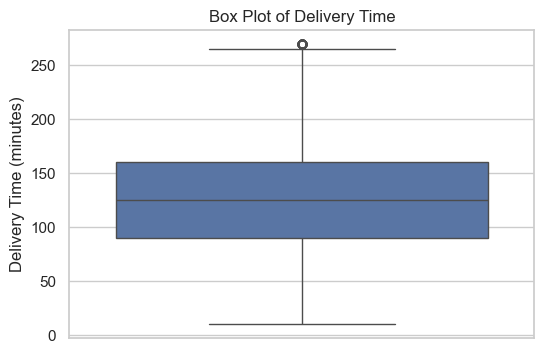

In [9]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df["Delivery_Time"])
plt.title("Box Plot of Delivery Time")
plt.ylabel("Delivery Time (minutes)")
plt.show()

In [12]:
df["Distance"].describe()

count    43648.000000
mean        27.255432
std        303.815765
min          1.465067
25%          4.663432
50%          9.220419
75%         13.682165
max       6884.726399
Name: Distance, dtype: float64

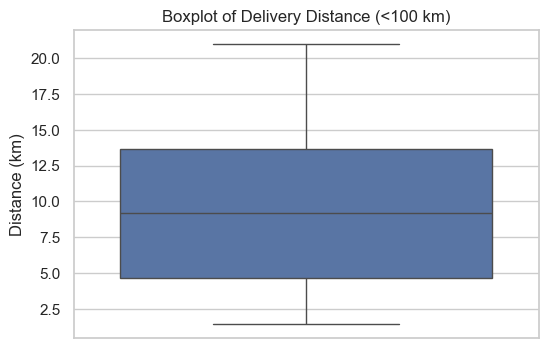

In [22]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df[df["Distance"] < 100]["Distance"])
plt.title("Boxplot of Delivery Distance (<100 km)")
plt.ylabel("Distance (km)")
plt.show()

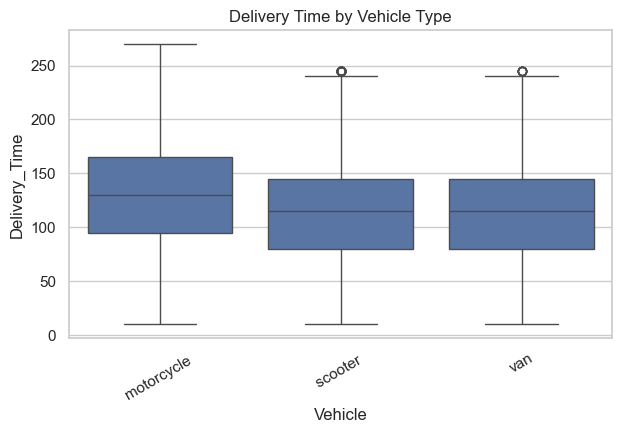

In [23]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Vehicle", y="Delivery_Time", data=df)
plt.xticks(rotation=30)
plt.title("Delivery Time by Vehicle Type")
plt.show()

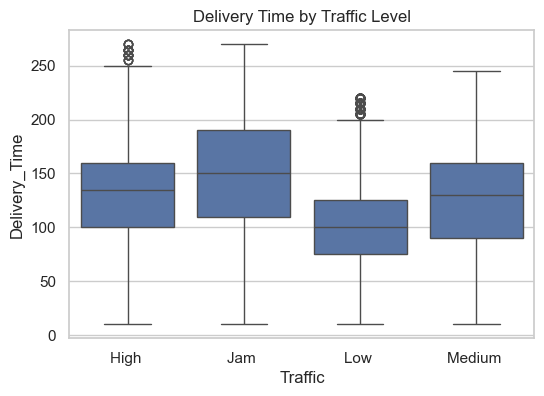

In [24]:
plt.figure(figsize=(6,4))
sns.boxplot(x="Traffic", y="Delivery_Time", data=df)
plt.title("Delivery Time by Traffic Level")
plt.show()

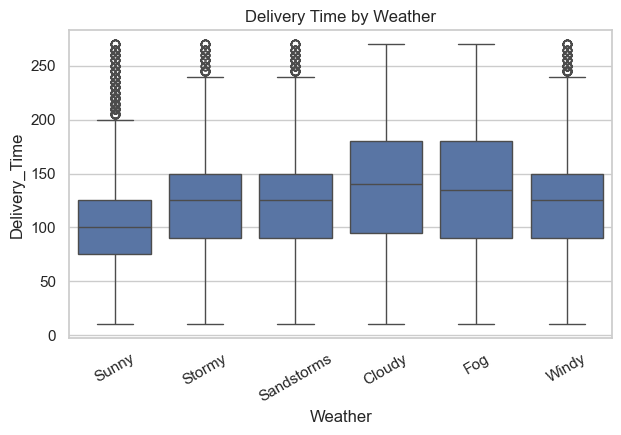

In [25]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Weather", y="Delivery_Time", data=df)
plt.xticks(rotation=30)
plt.title("Delivery Time by Weather")
plt.show()


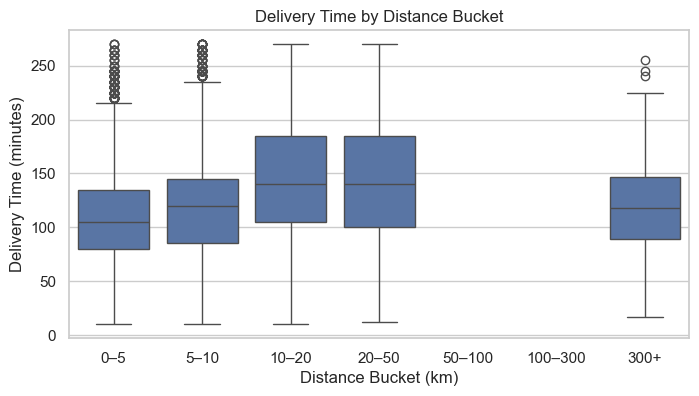

In [28]:
df["Distance_Bucket"] = pd.cut(
    df["Distance"],
    bins=[0, 5, 10, 20, 50, 100, 300, df["Distance"].max()],
    labels=["0–5", "5–10", "10–20", "20–50", "50–100", "100–300", "300+"]
)
plt.figure(figsize=(8,4))
sns.boxplot(x="Distance_Bucket", y="Delivery_Time", data=df)
plt.title("Delivery Time by Distance Bucket")
plt.xlabel("Distance Bucket (km)")
plt.ylabel("Delivery Time (minutes)")
plt.show()


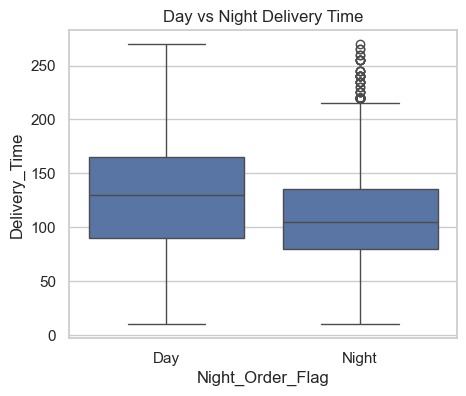

In [29]:
plt.figure(figsize=(5,4))
sns.boxplot(x="Night_Order_Flag", y="Delivery_Time", data=df)
plt.xticks([0,1], ["Day", "Night"])
plt.title("Day vs Night Delivery Time")
plt.show()

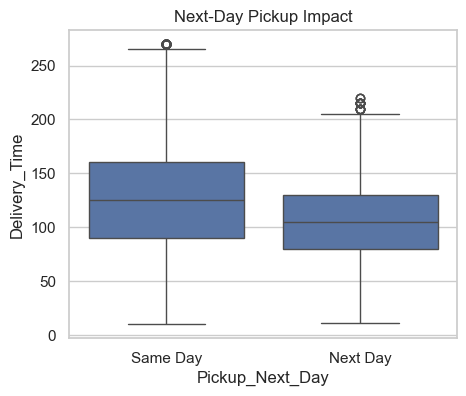

In [34]:
plt.figure(figsize=(5,4))
sns.boxplot(x="Pickup_Next_Day", y="Delivery_Time", data=df)
plt.xticks([0,1], ["Same Day", "Next Day"])
plt.title("Next-Day Pickup Impact")
plt.show()

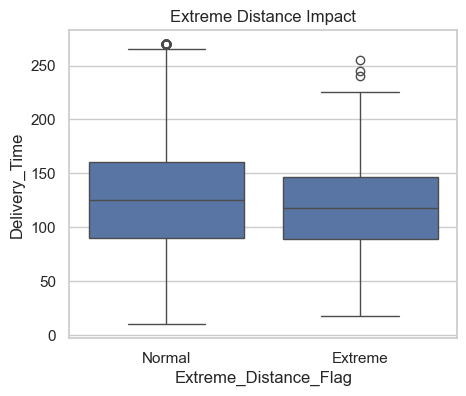

In [35]:
plt.figure(figsize=(5,4))
sns.boxplot(x="Extreme_Distance_Flag", y="Delivery_Time", data=df)
plt.xticks([0,1], ["Normal", "Extreme"])
plt.title("Extreme Distance Impact")
plt.show()

At the end of the notebook, add markdown answering:

Which factors clearly increase delivery time?

Which features look noisy or weak?

Which flags seem useful?

What surprised you?